In [1]:
# ---- setup -----------------------------------------------------------------
import os, sys, glob, json, time
from pathlib import Path
NB_START = time.time()

CODE_DIR = Path("/kaggle/working/code"); CODE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = sorted(d for d in glob.glob("/kaggle/input/**/m4raw_cache", recursive=True)
                   if os.path.isdir(os.path.join(d, "train")))[0]
print("cache:", CACHE_DIR)
print("earlier runs attached:", sorted({Path(p).parent.name for p in glob.glob("/kaggle/input/**/runs/*/last.pt", recursive=True)}))

cache: /kaggle/input/datasets/mahimasunilbachhav/m4raw-sgf-cache/m4raw_cache
earlier runs attached: ['dcamsr_sr2', 'dcamsr_sr4', 'sgf_mri_sr2', 'sgf_mri_sr4', 'unet_multi_sr4', 'unet_single_sr4']


In [2]:
%%writefile /kaggle/working/code/sgf_train.py
"""
Week-2 toolkit for reproducing SGF-MRI on M4Raw (T1 reference -> T2 target).

Contents
  * models      : Bicubic / zero-filled baseline, single- and multi-contrast U-Net
  * train()     : L1 loss, Adam 2e-4, StepLR(40, 0.1), batch 4  (SGF-MRI Sec. 4.1)
                  checkpoint every epoch, auto-resume, stops cleanly before Kaggle's 12 h limit
  * evaluate()  : PSNR / SSIM per volume, exactly as DCAMSR/fastMRI compute them
  * profile()   : parameters, peak GPU memory, inference time per slice

Every model uses DCAMSR's call signature  model(lr, ref, ref_down)
    lr       (B,1,h,w)  degraded T2 (LR image for SR, zero-filled image for reconstruction)
    ref      (B,1,H,W)  fully sampled T1
    ref_down (B,1,h,w)  T1 degraded the same way as the input (SR only)
and returns (B,1,H,W).  DCAMSR and SGF-MRI will plug in later with no other changes.
"""
from __future__ import annotations

import csv
import glob
import json
import math
import os
import random
import shutil
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from m4raw_dataset import M4RawPairs
from m4raw_prep import fft2c, ifft2c


# =========================================================================== #
# Locating the cache on Kaggle
# =========================================================================== #
def find_cache_dir() -> str:
    hits = sorted(glob.glob("/kaggle/input/**/m4raw_cache", recursive=True))
    hits = [h for h in hits if os.path.isdir(os.path.join(h, "train"))]
    if not hits:
        raise FileNotFoundError("m4raw_cache not found: Add Input -> Your Datasets -> your cache dataset")
    return hits[0]


# =========================================================================== #
# Dataset: same as M4RawPairs, plus a choice of which axis the recon mask drops
# =========================================================================== #
class M4RawTask(M4RawPairs):
    """
    mask_axis = -1 : drop k-space columns (fastMRI convention, default in m4raw_dataset)
    mask_axis = -2 : drop k-space rows    (the SGF-MRI paper text says "rows")
    """

    def __init__(self, *a, mask_axis: int = -1, preload: bool = False, **kw):
        super().__init__(*a, **kw)
        assert mask_axis in (-1, -2)
        self.mask_axis = mask_axis
        self._ram = None
        if preload:
            self._preload()

    # ---- optional: hold the needed arrays in RAM ---------------------------
    # Reading every slice from the HDF5 files inside the data-loader workers made
    # RAM use creep up for hours and finally got the run killed (commit log, 29 Oct);
    # as RAM filled, the OS dropped its file cache and epochs slowed from 2.4 to 23 min.
    # Preloading reads each file ONCE, sequentially; workers then only slice arrays
    # (forked workers share these pages; nothing is copied).
    def _needed_keys(self):
        keys = ["tar_hr", "ref_hr"]
        if self.task == "sr":
            keys += [f"tar_lr{self.scale}", f"ref_lr{self.scale}"]
        return keys

    def _preload(self):
        import h5py
        t0 = time.time()
        keys = self._needed_keys()
        total = len(self.examples)
        self._row, start = {}, 0
        with h5py.File(self.files[0], "r") as hf:
            shapes = {k: hf[k].shape[1:] for k in keys}
        self._ram = {k: np.empty((total,) + shapes[k], np.float32) for k in keys}   # allocated once, filled in place
        for f in self.files:
            with h5py.File(f, "r") as hf:
                n = int(hf.attrs["num_slices"])
                for k in keys:
                    hf[k].read_direct(self._ram[k], np.s_[:n], np.s_[start:start + n])
            self._row[f] = start
            start += n
        assert start == total
        gb = sum(a.nbytes for a in self._ram.values()) / 2**30
        print(f"[{_now()}] preloaded {len(self.files)} volumes / {total} slices ({gb:.1f} GB) "
              f"in {time.time() - t0:.0f} s", flush=True)

    def __getitem__(self, i):
        if self._ram is None:
            return super().__getitem__(i)
        from m4raw_dataset import _norm
        path, s = self.examples[i]
        r = self._row[path] + s
        tar_hr = self._ram["tar_hr"][r]
        ref_hr = self._ram["ref_hr"][r]
        if self.task == "sr":
            tar_in = self._ram[f"tar_lr{self.scale}"][r]
            ref_in = self._ram[f"ref_lr{self.scale}"][r]
            mask = np.ones(1, np.float32)
        else:
            tar_in, mask = self._zero_filled(tar_hr, path.stem)
            ref_in = ref_hr
        # identical to M4RawPairs.__getitem__ (DCAMSR normalisation; ddof=1 like torch .std())
        mean, std = tar_in.mean(), tar_in.std(ddof=1)
        rmean, rstd = ref_in.mean(), ref_in.std(ddof=1)
        sample = {"input": _norm(tar_in, mean, std), "target": _norm(tar_hr, mean, std),
                  "ref": _norm(ref_hr, rmean, rstd), "ref_in": _norm(ref_in, rmean, rstd),
                  "mask": mask, "mean": np.float32(mean), "std": np.float32(std),
                  "fname": path.stem, "slice": s}
        for k in ("input", "target", "ref", "ref_in", "mask"):
            sample[k] = torch.from_numpy(sample[k])
        return sample

    def _zero_filled(self, img, name):
        from m4raw_dataset import _seed_from_name
        seed = _seed_from_name(name) if self.deterministic else None
        n = img.shape[self.mask_axis]
        mask = self.mask_func(n, seed)
        m2d = mask[None, :] if self.mask_axis == -1 else mask[:, None]
        k = fft2c(img.astype(np.complex64)) * m2d
        return np.abs(ifft2c(k)).astype(np.float32), mask


def worker_init_fn(_):
    """Give every DataLoader worker its own random-mask stream.
    Without this, all workers start from the same copied RandomState and
    produce identical 'random' masks (a classic numpy + DataLoader bug)."""
    info = torch.utils.data.get_worker_info()
    ds = info.dataset
    seed = info.seed % 2**32
    np.random.seed(seed)
    random.seed(seed)
    if hasattr(ds, "mask_func"):
        ds.mask_func.rng = np.random.RandomState(seed)


def make_dataset(cache_dir, split, cfg: "Config", max_pairs=None, preload=None):
    preload = getattr(cfg, "preload", False) if preload is None else preload
    return M4RawTask(cache_dir, split, task=cfg.task, scale=cfg.scale, accel=cfg.accel,
                     mask_axis=cfg.mask_axis, max_pairs=max_pairs, preload=preload)


# =========================================================================== #
# Models
# =========================================================================== #
def upsample_to(x, hw, mode="bicubic"):
    if tuple(x.shape[-2:]) == tuple(hw):
        return x
    return F.interpolate(x, size=hw, mode=mode, align_corners=False)


class Bicubic(nn.Module):
    """
    No learning. SR: bicubic upsampling of the LR image. Recon: the zero-filled image itself.

    DCAMSR makes LR images by cropping the centre of k-space with an orthonormal FFT,
    which leaves them `scale` times BRIGHTER than the HR image (2x / 4x). Trained
    networks learn this (DCAMSR and SGF-MRI were trained on exactly this data), but a
    plain interpolation cannot, so evaluate() divides this model's de-normalised output
    by `intensity_divisor`.
    """

    def __init__(self, scale: int = 1, **_):
        super().__init__()
        self.intensity_divisor = float(scale)
        self.dummy = nn.Parameter(torch.zeros(()), requires_grad=False)

    def forward(self, lr, ref, ref_down=None):
        return upsample_to(lr, ref.shape[-2:])


def _norm_layer(c, norm):
    return nn.InstanceNorm2d(c) if norm == "instance" else nn.Identity()


class ConvBlock(nn.Module):
    def __init__(self, cin, cout, norm="none"):
        super().__init__()
        bias = norm == "none"
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=bias), _norm_layer(cout, norm), nn.LeakyReLU(0.2, True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=bias), _norm_layer(cout, norm), nn.LeakyReLU(0.2, True))

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    """
    fastMRI-style U-Net (conv-LeakyReLU x2, avg-pool down, transpose-conv up).
    norm="none" by default: with DCAMSR's data the model must recover each image's
    absolute brightness level (LR is `scale`x brighter than HR), and InstanceNorm
    erases exactly that information (tested: single-contrast SR stalls with it).
    """

    def __init__(self, in_chans=1, out_chans=1, chans=32, num_pools=3, norm="none"):
        super().__init__()
        self.num_pools = num_pools
        self.down = nn.ModuleList([ConvBlock(in_chans, chans, norm)])
        c = chans
        for _ in range(num_pools - 1):
            self.down.append(ConvBlock(c, c * 2, norm)); c *= 2
        self.bottom = ConvBlock(c, c * 2, norm)
        self.up_t, self.up_c = nn.ModuleList(), nn.ModuleList()
        for _ in range(num_pools):
            self.up_t.append(nn.Sequential(nn.ConvTranspose2d(c * 2, c, 2, stride=2, bias=norm == "none"),
                                           _norm_layer(c, norm), nn.LeakyReLU(0.2, True)))
            self.up_c.append(ConvBlock(c * 2, c, norm)); c //= 2
        self.out = nn.Conv2d(chans, out_chans, 1)

    def forward(self, x):
        h, w = x.shape[-2:]
        m = 2 ** self.num_pools                      # pad so every pooling divides evenly
        ph, pw = (-h) % m, (-w) % m
        x = F.pad(x, (pw // 2, pw - pw // 2, ph // 2, ph - ph // 2), mode="reflect")
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = F.avg_pool2d(x, 2)
        x = self.bottom(x)
        for t, c in zip(self.up_t, self.up_c):
            x = c(torch.cat([t(x), skips.pop()], 1))
        x = self.out(x)
        return x[..., ph // 2: ph // 2 + h, pw // 2: pw // 2 + w]


class UNetRestorer(nn.Module):
    """
    Upsample the degraded T2 to full size, then predict a residual correction.
      use_ref=False : single-contrast baseline (T2 only)
      use_ref=True  : plain multi-contrast baseline (T1 concatenated as a 2nd channel)
    The pair (single vs multi) is the "does the reference help?" first row of Fig. 5a.
    """

    def __init__(self, use_ref=False, chans=32, num_pools=3, norm="none", **_):
        super().__init__()
        self.use_ref = use_ref
        self.unet = UNet(in_chans=2 if use_ref else 1, chans=chans, num_pools=num_pools, norm=norm)

    def forward(self, lr, ref, ref_down=None):
        up = upsample_to(lr, ref.shape[-2:])
        inp = torch.cat([up, ref], 1) if self.use_ref else up
        return up + self.unet(inp)


MODELS = {
    "bicubic": lambda cfg: Bicubic(cfg.scale if cfg.task == "sr" else 1),
    "unet_single": lambda cfg: UNetRestorer(False, cfg.chans, cfg.num_pools, cfg.norm),
    "unet_multi": lambda cfg: UNetRestorer(True, cfg.chans, cfg.num_pools, cfg.norm),
    # DCAMSR (MICCAI 2023), ported verbatim in models_dcamsr.py; scale 1 = reconstruction
    "dcamsr": lambda cfg: __import__("models_dcamsr").DCAMSR(
        scale=cfg.scale if cfg.task == "sr" else 1, img_size=cfg.img_size),
    # SGF-MRI (this project's implementation, models_sgfmri.py); scale 1 = reconstruction
    "sgf_mri": lambda cfg: __import__("models_sgfmri").SGFMRI(
        scale=cfg.scale if cfg.task == "sr" else 1, groups=cfg.sgf_groups, window=cfg.sfa_window,
        sfa_mode=cfg.sfa_mode, intra=cfg.sgf_intra, cross=cfg.sgf_cross, san=cfg.sgf_san,
        separate_encoders=cfg.sgf_separate_encoders),
}


def build_model(cfg: "Config") -> nn.Module:
    if cfg.model not in MODELS:
        raise KeyError(f"unknown model {cfg.model!r}; choose from {list(MODELS)}")
    return MODELS[cfg.model](cfg)


def count_params(model) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# =========================================================================== #
# Config
# =========================================================================== #
@dataclass
class Config:
    run_name: str = "unet_single_sr4"
    model: str = "unet_single"
    task: str = "sr"                 # "sr" or "recon"
    scale: int = 4                   # SR factor (2 or 4)
    accel: int = 4                   # recon acceleration (4 or 8)
    mask_axis: int = -1              # recon: -1 columns (fastMRI) / -2 rows (paper text)
    chans: int = 32
    num_pools: int = 3               # paper: "encoder-decoder has 3 layers"
    norm: str = "none"               # U-Net normalisation: "none" | "instance"
    epochs: int = 50                 # not given in the paper; DCAMSR's train.py uses 50
    batch_size: int = 4              # paper (DCAMSR's own code: 4 per GPU x 8 GPUs)
    accum_steps: int = 1             # gradient accumulation: batch_size=2, accum_steps=2 behaves like batch 4
                                     # with half the GPU memory (fallback if a model does not fit)
    img_size: int = 256              # set automatically from the data (DCAMSR's attention depends on it)
    # SGF-MRI options (paper values where stated; see the implementation spec for the rest)
    sgf_groups: int = 8              # n channel groups (paper: n = 8)
    sfa_mode: str = "window"         # SFA attention: "window" (local, linear cost) | "channel"
    sfa_window: int = 8              # window size for sfa_mode="window"
    sgf_intra: bool = True           # ablation switches (paper Fig. 5a)
    sgf_cross: bool = True
    sgf_san: bool = True
    sgf_separate_encoders: bool = False
    lr: float = 2e-4                 # paper
    lr_step: int = 40                # paper
    lr_gamma: float = 0.1            # paper
    num_workers: int = 4             # training data-loader processes
    eval_workers: int = 2            # evaluation data-loader processes (kept small: they run beside the training ones)
    amp: bool = True                 # mixed precision on GPU (~2x faster, less memory)
    multi_gpu: bool = False          # DataParallel over 2 GPUs. Slower than 1 GPU for this small model;
                                     # better: train two models at once, one per GPU (notebook 02, step C)
    log_every: int = 200             # progress + RAM/GPU line every N iterations
    preload: bool = True             # hold this task's arrays in RAM (~4.7 GB for SR x4, train + test)
    seed: int = 42
    val_every: int = 5               # full test-set evaluation every N epochs (+ last epoch)
    time_budget_h: float = 11.0      # stop cleanly before Kaggle's 12 h session limit
    max_train_pairs: Optional[int] = None   # small numbers = quick smoke test
    max_val_pairs: Optional[int] = None
    out_root: str = "/kaggle/working/runs"

    @property
    def out_dir(self) -> Path:
        return Path(self.out_root) / self.run_name

    def describe(self):
        deg = f"SR x{self.scale}" if self.task == "sr" else f"recon {self.accel}x (mask axis {self.mask_axis})"
        return f"{self.model} | {deg}"


# =========================================================================== #
# Evaluation (DCAMSR / fastMRI protocol)
# =========================================================================== #
def _volume_scores(gt, pred):
    """fastmri/evaluate.py: data_range = volume max; SSIM averaged over slices."""
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity
    dr = float(gt.max())
    p = peak_signal_noise_ratio(gt, pred, data_range=dr)
    s = float(np.mean([structural_similarity(g, q, data_range=dr) for g, q in zip(gt, pred)]))
    return p, s


@torch.no_grad()
def evaluate(model, dataset, device, batch_size=8, num_workers=4, amp=True, keep_examples=0):
    """
    Runs the whole split in order, rebuilds each volume, de-normalises with
    x * std + mean (the GT is the de-normalised, [-6,6]-clipped target, exactly
    what DCAMSR's validation_step compares against), and scores per volume.
    Returns metrics dict (+ a list of example slices if keep_examples > 0).
    """
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=device.type == "cuda")
    use_amp = amp and device.type == "cuda"
    n_slices = {}
    for path, s in dataset.examples:
        n_slices[path.stem] = n_slices.get(path.stem, 0) + 1
    psnrs, ssims, names, examples = [], [], [], []
    cur, preds, gts = None, [], []

    def flush():
        if cur is None:
            return
        p, s = _volume_scores(np.stack(gts), np.stack(preds))
        psnrs.append(p); ssims.append(s); names.append(cur)

    for b in loader:
        lr = b["input"].unsqueeze(1).to(device)
        ref = b["ref"].unsqueeze(1).to(device)
        ref_in = b["ref_in"].unsqueeze(1).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            out = model(lr, ref, ref_in)
        out = out.float().squeeze(1).cpu().numpy()
        mean = b["mean"].numpy()[:, None, None]
        std = b["std"].numpy()[:, None, None]
        out = (out * std + mean) / getattr(model, "intensity_divisor", 1.0)
        tgt = b["target"].numpy() * std + mean
        for i, name in enumerate(b["fname"]):
            if name != cur:
                flush(); cur, preds, gts = name, [], []
            preds.append(out[i]); gts.append(tgt[i])
            if len(examples) < keep_examples and int(b["slice"][i]) == n_slices[name] // 2:
                examples.append({"name": name, "input": b["input"][i].numpy() * std[i] + mean[i],
                                 "output": out[i], "target": tgt[i], "ref": b["ref"][i].numpy()})
    flush()
    res = {"psnr": float(np.mean(psnrs)), "psnr_std": float(np.std(psnrs)),
           "ssim": float(np.mean(ssims)), "ssim_std": float(np.std(ssims)),
           "n_volumes": len(psnrs),
           "per_volume": {n: (p, s) for n, p, s in zip(names, psnrs, ssims)}}   # for paired tests
    return (res, examples) if keep_examples else res


# =========================================================================== #
# Per-volume scores + paired significance tests (as the paper's * marks)
# =========================================================================== #
def save_per_volume(res, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["volume", "subject", "psnr", "ssim"])
        for name, (p, s) in sorted(res["per_volume"].items()):
            w.writerow([name, name.split("_")[0], f"{p:.6f}", f"{s:.6f}"])


def load_per_volume(path):
    with open(path) as f:
        return {r["volume"]: (float(r["psnr"]), float(r["ssim"])) for r in csv.DictReader(f)}


def paired_test(per_a: dict, per_b: dict, metric="psnr", level="subject"):
    """
    Is model A better than model B on the SAME test scans?
      level="volume"  : n = 90 scans (30 people x 3 repeated scans). The repeats of one person
                        are not independent, so this overstates certainty; likely what papers report.
      level="subject" : average each person's 3 scans first, n = 30. The honest choice.
    Returns mean difference A-B, its 95% CI, paired t-test p, Wilcoxon signed-rank p, and
    how many scans/people A wins on.
    """
    from scipy import stats
    k = 0 if metric == "psnr" else 1
    common = sorted(set(per_a) & set(per_b))
    if level == "subject":
        groups = {}
        for v in common:
            groups.setdefault(v.split("_")[0], []).append(v)
        a = np.array([np.mean([per_a[v][k] for v in vs]) for vs in groups.values()])
        b = np.array([np.mean([per_b[v][k] for v in vs]) for vs in groups.values()])
    else:
        a = np.array([per_a[v][k] for v in common]); b = np.array([per_b[v][k] for v in common])
    d = a - b
    n = len(d)
    ci = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n) if n > 1 else float("nan")
    t_p = stats.ttest_rel(a, b).pvalue if n > 1 else float("nan")
    try:
        w_p = stats.wilcoxon(a, b).pvalue
    except ValueError:                           # all differences zero
        w_p = 1.0
    return {"n": n, "mean_diff": float(d.mean()), "ci95": float(ci), "t_p": float(t_p),
            "wilcoxon_p": float(w_p), "wins": int((d > 0).sum())}


def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."


# =========================================================================== #
# Checkpointing
# =========================================================================== #
def _save(state, path: Path):
    tmp = path.with_suffix(".tmp")
    torch.save(state, tmp)
    os.replace(tmp, path)                     # atomic: a crash never leaves a broken file


def _bring_previous_run(cfg: Config):
    """If this run is not in /kaggle/working, copy it from an attached previous version."""
    if (cfg.out_dir / "last.pt").exists():
        return
    hits = sorted(glob.glob(f"/kaggle/input/**/runs/{cfg.run_name}/last.pt", recursive=True))
    if hits:
        src = Path(hits[-1]).parent
        shutil.copytree(src, cfg.out_dir, dirs_exist_ok=True)
        print(f"[resume] copied previous run from {src}")


# =========================================================================== #
# Training
# =========================================================================== #
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def resources(device=None) -> str:
    """One short line: system RAM, this process's RAM, GPU memory, free disk."""
    parts = []
    try:
        import psutil
        vm = psutil.virtual_memory()
        rss = psutil.Process().memory_info().rss
        kids = sum(c.memory_info().rss for c in psutil.Process().children(recursive=True))
        parts.append(f"RAM {vm.used/2**30:.1f}/{vm.total/2**30:.0f} GB ({vm.percent:.0f}%)")
        parts.append(f"proc {rss/2**30:.1f} GB + workers {kids/2**30:.1f} GB")
    except Exception:
        pass
    if device is not None and device.type == "cuda":
        parts.append(f"GPU{torch.cuda.current_device()} {torch.cuda.memory_allocated()/2**30:.2f} GB "
                     f"(peak {torch.cuda.max_memory_allocated()/2**30:.2f})")
    try:
        parts.append(f"disk free {shutil.disk_usage('/kaggle/working' if os.path.isdir('/kaggle/working') else '.').free/2**30:.0f} GB")
    except Exception:
        pass
    return " | ".join(parts)


def _now():
    return time.strftime("%H:%M:%S")


def _arm_watchdog(minutes=30):
    """If nothing is logged for `minutes`, dump every thread's stack to the log (diagnoses hangs)."""
    import faulthandler, sys
    faulthandler.cancel_dump_traceback_later()
    faulthandler.dump_traceback_later(minutes * 60, repeat=True, file=sys.stderr)


def train(cfg: Config, cache_dir: str):
    import faulthandler, sys, traceback
    faulthandler.enable(file=sys.stderr)        # a hard crash (segfault) still prints where it happened
    t_start = time.time()
    seed_everything(cfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
    cfg.out_dir.mkdir(parents=True, exist_ok=True)
    _bring_previous_run(cfg)

    train_ds = make_dataset(cache_dir, "train", cfg, cfg.max_train_pairs)
    val_ds = make_dataset(cache_dir, "val", cfg, cfg.max_val_pairs)
    cfg.img_size = int(train_ds[0]["target"].shape[-1])       # 256 for M4Raw, 320 for fastMRI
    g = torch.Generator(); g.manual_seed(cfg.seed)
    train_dl = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                          num_workers=cfg.num_workers, pin_memory=device.type == "cuda",
                          worker_init_fn=worker_init_fn, generator=g,
                          persistent_workers=cfg.num_workers > 0)

    model = build_model(cfg).to(device)
    n_params = count_params(model)
    net = nn.DataParallel(model) if (cfg.multi_gpu and torch.cuda.device_count() > 1) else model
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.StepLR(opt, cfg.lr_step, cfg.lr_gamma)
    use_amp = cfg.amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    start_epoch, best, history = 0, -math.inf, []
    last = cfg.out_dir / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optim"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start_epoch, best, history = ck["epoch"] + 1, ck["best_psnr"], ck["history"]
        print(f"[resume] continuing from epoch {start_epoch} (best PSNR so far {best:.3f})")
    (cfg.out_dir / "config.json").write_text(json.dumps(asdict(cfg), indent=2))

    gpu_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "cpu"
    print(f"[{_now()}] {cfg.run_name}: {cfg.describe()} | params {n_params/1e6:.2f} M | {gpu_name}"
          f"{' x' + str(torch.cuda.device_count()) if isinstance(net, nn.DataParallel) else ''} | "
          f"train {len(train_ds)} slices ({len(train_dl)} it/epoch) | test {len(val_ds)} slices | "
          f"budget {cfg.time_budget_h:.1f} h", flush=True)
    print(f"[{_now()}] {resources(device)}", flush=True)
    if start_epoch >= cfg.epochs:
        print("already finished"); return history

    epoch_times = []
    _arm_watchdog()
    for epoch in range(start_epoch, cfg.epochs):
        t0 = time.time()
        net.train()
        tot, n = 0.0, 0
        t_last, t_wait = time.time(), 0.0
        t_fetch = time.time()
        for it, b in enumerate(train_dl):
            t_wait += time.time() - t_fetch      # time spent waiting for data
            lr_img = b["input"].unsqueeze(1).to(device, non_blocking=True)
            ref = b["ref"].unsqueeze(1).to(device, non_blocking=True)
            ref_in = b["ref_in"].unsqueeze(1).to(device, non_blocking=True)
            tgt = b["target"].unsqueeze(1).to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                out = net(lr_img, ref, ref_in)
            loss = F.l1_loss(out.float(), tgt)
            scaler.scale(loss / cfg.accum_steps).backward()
            if (it + 1) % cfg.accum_steps == 0:
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"loss became {loss.item()} at epoch {epoch} iter {it}")
            tot += loss.item(); n += 1
            if (it + 1) % cfg.log_every == 0 or it == 0:
                k = 1 if it == 0 else cfg.log_every
                dt = time.time() - t_last
                print(f"[{_now()}] ep {epoch:3d} it {it+1:5d}/{len(train_dl)} loss {loss.item():.4f} | "
                      f"{dt/k:.3f} s/it ({100*t_wait/max(dt,1e-9):.0f}% waiting for data) | {resources(device)}",
                      flush=True)
                t_last, t_wait = time.time(), 0.0
                _arm_watchdog()
            t_fetch = time.time()
        lr_used = opt.param_groups[0]["lr"]
        sched.step()
        rec = {"epoch": epoch, "lr": lr_used, "train_l1": tot / max(n, 1),
               "train_min": (time.time() - t0) / 60}

        # Save the epoch FIRST, so a problem during evaluation can never lose the training.
        history.append(rec)
        _save({"model": model.state_dict(), "optim": opt.state_dict(), "sched": sched.state_dict(),
               "scaler": scaler.state_dict(), "epoch": epoch, "best_psnr": best,
               "history": history, "cfg": asdict(cfg)}, last)
        _write_log(history, cfg.out_dir / "log.csv")

        do_val = (epoch + 1) % cfg.val_every == 0 or epoch + 1 == cfg.epochs
        if do_val:
            tv = time.time()
            print(f"[{_now()}] ep {epoch:3d} evaluating on {len(val_ds)} test slices ... | {resources(device)}",
                  flush=True)
            try:
                m = evaluate(model, val_ds, device, num_workers=cfg.eval_workers, amp=cfg.amp)
                rec.update({k: m[k] for k in ("psnr", "psnr_std", "ssim", "ssim_std")})
                if m["psnr"] > best:
                    best = m["psnr"]
                    _save({"model": model.state_dict(), "epoch": epoch, "metrics": m, "cfg": asdict(cfg)},
                          cfg.out_dir / "best.pt")
            except Exception as e:                # log it and keep training
                rec["val_error"] = f"{type(e).__name__}: {e}"
                print(f"[{_now()}] EVALUATION FAILED (training continues):", flush=True)
                traceback.print_exc()
            rec["val_min"] = (time.time() - tv) / 60
            if device.type == "cuda":
                torch.cuda.empty_cache()
            _save({"model": model.state_dict(), "optim": opt.state_dict(), "sched": sched.state_dict(),
                   "scaler": scaler.state_dict(), "epoch": epoch, "best_psnr": best,
                   "history": history, "cfg": asdict(cfg)}, last)
            _write_log(history, cfg.out_dir / "log.csv")
            _arm_watchdog()

        epoch_times.append(time.time() - t0)
        msg = f"[{_now()}] epoch {epoch:3d} done | L1 {rec['train_l1']:.4f} | {epoch_times[-1]/60:.1f} min"
        if "psnr" in rec:
            msg += (f" | test PSNR {rec['psnr']:.2f} SSIM {rec['ssim']:.4f} (best {best:.2f}) "
                    f"| eval {rec['val_min']:.1f} min")
        print(msg + f" | total {(time.time()-t_start)/3600:.2f} h", flush=True)

        elapsed = time.time() - t_start
        if epoch + 1 < cfg.epochs and elapsed + 1.5 * max(epoch_times[-3:]) > cfg.time_budget_h * 3600:
            print(f"[{_now()}] [time budget] stopping after epoch {epoch} ({elapsed/3600:.1f} h). "
                  f"Run again (attach this version's output as input) to resume.", flush=True)
            break
    import faulthandler
    faulthandler.cancel_dump_traceback_later()
    return history


def _write_log(history, path):
    keys = sorted({k for r in history for k in r}, key=lambda k: (k != "epoch", k))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(history)


def load_for_eval(cfg: Config, which="best", device=None):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ck = torch.load(cfg.out_dir / f"{which}.pt", map_location=device, weights_only=False)
    if "img_size" in ck.get("cfg", {}):
        cfg.img_size = ck["cfg"]["img_size"]
    model = build_model(cfg).to(device)
    model.load_state_dict(ck["model"])
    return model, ck.get("epoch")


def find_run_dir(run_name, out_root="/kaggle/working/runs"):
    """A finished run in this session, else in any attached input (an earlier notebook's output)."""
    here = Path(out_root) / run_name
    if (here / "last.pt").exists():
        return here
    hits = sorted(glob.glob(f"/kaggle/input/**/runs/{run_name}/last.pt", recursive=True))
    return Path(hits[-1]).parent if hits else None


def load_run(run_name, which="last", device=None, out_root="/kaggle/working/runs"):
    """Rebuild a trained model from its own saved config. Returns (model, cfg, epoch) or None."""
    d = find_run_dir(run_name, out_root)
    if d is None or not (d / f"{which}.pt").exists():
        return None
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ck = torch.load(d / f"{which}.pt", map_location=device, weights_only=False)
    fields = set(Config.__dataclass_fields__)
    cfg = Config(**{k: v for k, v in ck["cfg"].items() if k in fields})
    model = build_model(cfg).to(device)
    model.load_state_dict(ck["model"])
    return model, cfg, ck.get("epoch")


# =========================================================================== #
# Efficiency (paper Sec. 4.4: memory / time / parameters)
# =========================================================================== #
@torch.no_grad()
def profile(model, cfg: Config, hw=None, repeats=50):
    device = next(model.parameters()).device
    H, W = hw or (cfg.img_size, cfg.img_size)
    h, w = (H // cfg.scale, W // cfg.scale) if cfg.task == "sr" else (H, W)
    lr = torch.randn(1, 1, h, w, device=device)
    ref = torch.randn(1, 1, H, W, device=device)
    ref_in = torch.randn(1, 1, h, w, device=device)
    model.eval()
    for _ in range(5):
        model(lr, ref, ref_in)
    if device.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.time()
    for _ in range(repeats):
        model(lr, ref, ref_in)
    if device.type == "cuda":
        torch.cuda.synchronize()
    out = {"params_M": count_params(model) / 1e6, "sec_per_slice": (time.time() - t) / repeats}
    if device.type == "cuda":
        out["peak_mem_MB"] = torch.cuda.max_memory_allocated() / 2**20
    return out


# =========================================================================== #
# Paper numbers (M4Raw rows of Tables 1 and 2) for side-by-side comparison
# =========================================================================== #
PAPER_M4RAW = {
    ("sr", 2):    {"SwinIR": (32.16, 0.777), "DCAMSR": (32.31, 0.779), "SGF-MRI": (32.42, 0.781)},
    ("sr", 4):    {"SwinIR": (29.73, 0.709), "DCAMSR": (30.48, 0.728), "SGF-MRI": (30.62, 0.731)},
    ("recon", 4): {"SwinIR": (29.12, 0.692), "DCAMSR": (29.62, 0.706), "SGF-MRI": (29.82, 0.716)},
    ("recon", 8): {"SwinIR": (27.93, 0.621), "DCAMSR": (28.09, 0.658), "SGF-MRI": (28.27, 0.666)},
}


def paper_key(cfg: Config):
    return (cfg.task, cfg.scale if cfg.task == "sr" else cfg.accel)


def append_result(row: dict, path="/kaggle/working/results.csv"):
    path = Path(path)
    rows = []
    if path.exists():
        with open(path) as f:
            rows = list(csv.DictReader(f))
    rows = [r for r in rows if not (r.get("run") == row["run"] and r.get("checkpoint") == row.get("checkpoint"))]
    rows.append({k: (f"{v:.4f}" if isinstance(v, float) else v) for k, v in row.items()})
    keys = list(dict.fromkeys(k for r in rows for k in r))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(rows)


# =========================================================================== #
# Running training as separate processes (robust Kaggle commits)
# =========================================================================== #
EXIT_MEANING = {0: "finished OK", 1: "Python error (traceback in its log)",
                -9: "KILLED by the system - almost always out of RAM",
                137: "KILLED by the system - almost always out of RAM",
                -15: "terminated", -11: "crashed (segmentation fault)"}


def _tail(path, n=25):
    try:
        with open(path, "rb") as f:
            f.seek(0, 2); size = f.tell(); f.seek(max(0, size - 20000))
            return f.read().decode(errors="replace").splitlines()[-n:]
    except OSError:
        return []


def launch_jobs(jobs, cache_dir, code_dir, session_hours=11.0, poll_minutes=10, out_root=None):
    """
    Trains each Config in `jobs` in its OWN Python process, one GPU each (round-robin),
    all at the same time, and waits for them. Output of job X goes to runs/X/train.log.

    Why a separate process: if training crashes or is killed (e.g. out of memory),
    only that process dies; this notebook keeps running, reports the reason, and the
    Kaggle commit still finishes, so every checkpoint written so far is saved.
    Returns {run_name: exit_code}.
    """
    import subprocess, sys
    t0 = time.time()
    n_gpu = torch.cuda.device_count()
    cpus = os.cpu_count() or 2
    procs = {}
    for i, cfg in enumerate(jobs):
        if out_root:
            cfg.out_root = out_root
        cfg.num_workers = max(1, cpus // len(jobs))
        cfg.eval_workers = max(1, min(2, cfg.num_workers))
        cfg.time_budget_h = session_hours
        cfg.multi_gpu = False
        cfg.out_dir.mkdir(parents=True, exist_ok=True)
        _bring_previous_run(cfg)                      # resume files in place before logging starts
        cfg_path = cfg.out_dir / "launch_config.json"
        cfg_path.write_text(json.dumps(asdict(cfg), indent=2))
        env = dict(os.environ, PYTHONUNBUFFERED="1", MALLOC_ARENA_MAX="2",   # limits glibc memory fragmentation
                   PYTHONPATH=os.pathsep.join([str(code_dir), str(cache_dir), os.environ.get("PYTHONPATH", "")]))
        gpu = f"GPU {i % n_gpu}" if n_gpu else "CPU"
        if n_gpu:
            env["CUDA_VISIBLE_DEVICES"] = str(i % n_gpu)
        log_path = cfg.out_dir / "train.log"
        log = open(log_path, "a")
        log.write(f"\n===== launch {time.strftime('%Y-%m-%d %H:%M:%S')} on {gpu} =====\n"); log.flush()
        p = subprocess.Popen([sys.executable, "-u", str(Path(code_dir) / "sgf_train.py"),
                              "--config", str(cfg_path), "--cache", str(cache_dir)],
                             stdout=log, stderr=subprocess.STDOUT, env=env)
        procs[cfg.run_name] = (p, log_path, log)
        print(f"[{_now()}] started {cfg.run_name} on {gpu} | {cfg.describe()} | "
              f"{cfg.num_workers} data workers | log: {log_path}", flush=True)

    codes = {}
    try:
        while len(codes) < len(procs):
            deadline = time.time() + poll_minutes * 60
            while time.time() < deadline and len(codes) < len(procs):
                time.sleep(5)
                for name, (p, lp, lf) in procs.items():
                    if name not in codes and p.poll() is not None:
                        codes[name] = p.returncode; lf.close()
                        print(f"[{_now()}] {name} ended: exit {p.returncode} = "
                              f"{EXIT_MEANING.get(p.returncode, 'unexpected exit')}", flush=True)
            print(f"[{_now()}] --- status after {(time.time()-t0)/3600:.2f} h | {resources()}", flush=True)
            for name, (p, lp, lf) in procs.items():
                last = next((l for l in reversed(_tail(lp, 40)) if l.startswith("[")), "(no progress line yet)")
                state = "running" if name not in codes else f"ended ({codes[name]})"
                print(f"    {name:20s} {state:12s} {last[:170]}", flush=True)
    except KeyboardInterrupt:
        print("interrupted: stopping the training processes (checkpoints so far are kept)")
        for name, (p, lp, lf) in procs.items():
            if p.poll() is None:
                p.terminate()
        for name, (p, lp, lf) in procs.items():
            try:
                p.wait(timeout=60)
            except Exception:
                p.kill()
            codes.setdefault(name, p.returncode)

    for name, (p, lp, lf) in procs.items():
        if codes.get(name) != 0:
            print(f"\n===== last lines of {lp} =====")
            print("\n".join(_tail(lp, 40)))
    return codes


def _cli():
    import argparse, traceback
    ap = argparse.ArgumentParser(description="train one SGF-MRI reproduction run")
    ap.add_argument("--config", required=True)
    ap.add_argument("--cache", required=True)
    a = ap.parse_args()
    cfg = Config(**json.loads(Path(a.config).read_text()))
    try:
        train(cfg, a.cache)
        print(f"[{_now()}] [done] {cfg.run_name}", flush=True)
        return 0
    except Exception:
        traceback.print_exc()
        return 1


if __name__ == "__main__":
    raise SystemExit(_cli())

Writing /kaggle/working/code/sgf_train.py


In [3]:
%%writefile /kaggle/working/code/models_dcamsr.py
"""
DCAMSR (Huang et al., MICCAI 2023), ported for this project.

Source: https://github.com/Solor-pikachu/DCAMSR  (branch SRV1.3, commit f42c64d),
file fastmri/models/archs/DCAMSR_arch.py.

Everything below is copied verbatim (only the two Chinese comments translated), except
the top-level DCAMSR class, which changes three things and nothing else:
  1. the image size is a parameter (the original hard-codes 256: right for M4Raw,
     fastMRI needs 320), because the spatial-attention projections depend on it;
  2. the constructor no longer takes the unused `args` argument;
  3. F.interpolate gets align_corners=False explicitly (the original relies on the
     default, which is the same value; this only silences a warning).
Layer names are unchanged, so weights trained with the original code load as-is.
Verified: identical outputs to the original module for the same weights.
"""
import functools

import torch
import torch.nn as nn
import torch.nn.functional as F


class DCAT(nn.Module):

    def __init__(
            self,
            input_size: int,
            hidden_size: int,
            proj_size: int = 64,
            num_heads: int = 8,
            dropout_rate: float = 0.1,
            pos_embed=True,
    ) -> None:
        """
        Args:
            input_size: the size of the input for each stage.
            hidden_size: dimension of hidden layer.
            proj_size: projection size for keys and values in the spatial attention module.
            num_heads: number of attention heads.
            dropout_rate: faction of the input units to drop.
            pos_embed: bool argument to determine if positional embedding is used.

        """

        super().__init__()

        if not (0 <= dropout_rate <= 1):
            raise ValueError("dropout_rate should be between 0 and 1.")

        if hidden_size % num_heads != 0:
            print("Hidden size is ", hidden_size)
            print("Num heads is ", num_heads)
            raise ValueError("hidden_size should be divisible by num_heads.")

        self.norm = nn.LayerNorm(hidden_size)
        # self.gamma = nn.Parameter(1e-6 * torch.ones(hidden_size), requires_grad=True)
        self.epa_block = DCA(input_size=input_size, input_size1=input_size,hidden_size=hidden_size, proj_size=proj_size, num_heads=num_heads, channel_attn_drop=dropout_rate,spatial_attn_drop=dropout_rate)

        if pos_embed:
            self.pos_embed = nn.Parameter(torch.zeros(1, input_size, hidden_size))
        else:
            self.pos_embed = None
            
        self.ffn = nn.Sequential(
            nn.Conv2d(in_channels=hidden_size,out_channels=hidden_size,kernel_size=1,stride=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=hidden_size,out_channels=hidden_size,kernel_size=1,stride=1),
        )

    def forward(self, x,ref):
        
        B, C, H, W = ref.shape
        ref = ref.reshape(B, C, H * W).permute(0, 2, 1)
        
        B, C, H, W = x.shape
        x = x.reshape(B, C, H * W).permute(0, 2, 1)

        if self.pos_embed is not None:
            x = x + self.pos_embed
            ref = ref + self.pos_embed
        attn = x + self.epa_block(self.norm(x),self.norm(ref))

        attn_skip = attn.reshape(B, H, W, C).permute(0, 3, 1, 2)  # (B, C, H, W)

        attn_skip = self.ffn(attn_skip) + attn_skip
        return attn_skip

class DCA(nn.Module):

    def __init__(self, input_size,input_size1, hidden_size, proj_size, num_heads=4, qkv_bias=True,
                 channel_attn_drop=0.1, spatial_attn_drop=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.temperature = nn.Parameter(torch.ones(num_heads, 1, 1))
        self.temperature2 = nn.Parameter(torch.ones(num_heads, 1, 1))

        self.q = nn.Linear(hidden_size,hidden_size)
        
        self.kvv = nn.Linear(hidden_size,hidden_size*3)
        
        self.E = self.F = nn.Linear(input_size1, proj_size)

        self.attn_drop = nn.Dropout(channel_attn_drop)
        self.attn_drop_2 = nn.Dropout(spatial_attn_drop)

        self.out_proj = nn.Linear(hidden_size, int(hidden_size // 2))
        self.out_proj2 = nn.Linear(hidden_size, int(hidden_size // 2))

    def forward(self, x,ref):
        B, N, C = x.shape
        B1,N1,C1 = ref.shape
        
        x = self.q(x)
        q_shared = x.reshape(B, N, self.num_heads, C // self.num_heads).permute(0, 2, 1, 3)
        
        kvv = self.kvv(ref).reshape(B, N, 3, self.num_heads, C // self.num_heads)
        kvv = kvv.permute(2, 0, 3, 1, 4)
        k_shared, v_CA, v_SA = kvv[0], kvv[1], kvv[2]

        #### channel attention
        q_shared = q_shared.transpose(-2, -1) #B,Head,C,N
        k_shared = k_shared.transpose(-2, -1)
        v_CA = v_CA.transpose(-2, -1)
        v_SA = v_SA.transpose(-2, -1)

        q_shared = torch.nn.functional.normalize(q_shared, dim=-1)
        k_shared = torch.nn.functional.normalize(k_shared, dim=-1)

        attn_CA = (q_shared @ k_shared.transpose(-2, -1)) * self.temperature # (B,Head,C,N) * (#B,Head,N,C) -> (B,Head,C,C)

        attn_CA = attn_CA.softmax(dim=-1) #B,Head,C,C
        attn_CA = self.attn_drop(attn_CA)

        x_CA = (attn_CA @ v_CA).permute(0, 3, 1, 2).reshape(B, N, C) # (B,Head,C,C) * (B,Head,C,N) -> (B,Head,C,N) -> (B,N,C)
        
        
        #### spatial attention
        k_shared_projected = self.E(k_shared)
        v_SA_projected = self.F(v_SA)

        attn_SA = (q_shared.permute(0, 1, 3, 2) @ k_shared_projected) * self.temperature2 # (B,Head,N,C) * (B,Head,C,64) -> (B,Head,N,64)

        attn_SA = attn_SA.softmax(dim=-1)
        attn_SA = self.attn_drop_2(attn_SA)

        x_SA = (attn_SA @ v_SA_projected.transpose(-2, -1)).permute(0, 3, 1, 2).reshape(B, N, C) # (B,Head,N,64) * (B,Head,64,C) -> (B,Head,N,C) -> (B,N,C)

        # Concat fusion
        x_CA = self.out_proj(x_CA)
        x_SA = self.out_proj2(x_SA)
        x = torch.cat((x_SA, x_CA), dim=-1)
        return x


def make_layer(block, n_layers):
    layers = []
    for _ in range(n_layers):
        layers.append(block())
    return nn.Sequential(*layers)


class ResidualBlock(nn.Module):
    def __init__(self, nf, kernel_size=3, stride=1, padding=1, dilation=1, act='relu'):
        super(ResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(nf, nf, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation)
        self.conv2 = nn.Conv2d(nf, nf, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation)

        if act == 'relu':
            self.act = nn.ReLU(inplace=True)
        else:
            self.act = nn.LeakyReLU(0.1, inplace=True)

    def forward(self, x):
        out = self.conv2(self.act(self.conv1(x)))

        return out + x


class SAM(nn.Module):
    def __init__(self, nf, use_residual=True, learnable=True):
        super(SAM, self).__init__()

        self.learnable = learnable
        self.norm_layer = nn.InstanceNorm2d(nf, affine=False)

        if self.learnable:
            self.conv_shared = nn.Sequential(nn.Conv2d(nf * 2, nf, 3, 1, 1, bias=True),
                                             nn.ReLU(inplace=True))
            self.conv_gamma = nn.Conv2d(nf, nf, 3, 1, 1, bias=True)
            self.conv_beta = nn.Conv2d(nf, nf, 3, 1, 1, bias=True)

            self.use_residual = use_residual

            # initialization
            self.conv_gamma.weight.data.zero_()
            self.conv_beta.weight.data.zero_()
            self.conv_gamma.bias.data.zero_()
            self.conv_beta.bias.data.zero_()

    def forward(self, lr, ref):
        ref_normed = self.norm_layer(ref)
        if self.learnable:
            style = self.conv_shared(torch.cat([lr, ref], dim=1))
            gamma = self.conv_gamma(style)
            beta = self.conv_beta(style)

        b, c, h, w = lr.size()
        lr = lr.view(b, c, h * w)
        lr_mean = torch.mean(lr, dim=-1, keepdim=True).unsqueeze(3)
        lr_std = torch.std(lr, dim=-1, keepdim=True).unsqueeze(3)

        if self.learnable:
            if self.use_residual:
                gamma = gamma + lr_std
                beta = beta + lr_mean
            else:
                gamma = 1 + gamma
        else:
            gamma = lr_std
            beta = lr_mean

        out = ref_normed * gamma + beta

        return out


class Encoder(nn.Module):
    def __init__(self, in_chl, nf, n_blks=[1, 1, 1], act='relu'):
        super(Encoder, self).__init__()

        block = functools.partial(ResidualBlock, nf=nf)

        self.conv_L1 = nn.Conv2d(in_chl, nf, 3, 1, 1, bias=True)
        self.blk_L1 = make_layer(block, n_layers=n_blks[0])

        self.conv_L2 = nn.Conv2d(nf, nf, 3, 2, 1, bias=True)
        self.blk_L2 = make_layer(block, n_layers=n_blks[1])

        self.conv_L3 = nn.Conv2d(nf, nf, 3, 2, 1, bias=True)
        self.blk_L3 = make_layer(block, n_layers=n_blks[2])

        if act == 'relu':
            self.act = nn.ReLU(inplace=True)
        else:
            self.act = nn.LeakyReLU(0.1, inplace=True)

    def forward(self, x):
        fea_L1 = self.blk_L1(self.act(self.conv_L1(x)))
        fea_L2 = self.blk_L2(self.act(self.conv_L2(fea_L1)))
        fea_L3 = self.blk_L3(self.act(self.conv_L3(fea_L2)))

        return [fea_L1, fea_L2, fea_L3]


class Decoder(nn.Module):
    def __init__(self, nf, out_chl, n_blks=[1, 1, 1, 1, 1, 1]):
        super(Decoder, self).__init__()

        block = functools.partial(ResidualBlock, nf=nf)

        self.conv_L3 = nn.Conv2d(nf, nf, 3, 2, 1, bias=True)
        self.blk_L3 = make_layer(block, n_layers=n_blks[0])

        self.conv_L2 = nn.Conv2d(nf, nf, 3, 1, 1, bias=True)
        self.blk_L2 = make_layer(block, n_layers=n_blks[1])

        self.conv_L1 = nn.Conv2d(nf * 2, nf, 3, 1, 1, bias=True)
        self.blk_L1 = make_layer(block, n_layers=n_blks[2])

        self.merge_warp_x1 = nn.Conv2d(nf * 2, nf, 3, 1, 1, bias=True)
        self.blk_x1 = make_layer(block, n_blks[3])

        self.merge_warp_x2 = nn.Conv2d(nf * 2, nf, 3, 1, 1, bias=True)
        self.blk_x2 = make_layer(block, n_blks[4])

        self.merge_warp_x4 = nn.Conv2d(nf * 2, nf, 3, 1, 1, bias=True)
        self.blk_x4 = make_layer(block, n_blks[5])

        self.conv_out = nn.Conv2d(64, out_chl, 3, 1, 1, bias=True)

        self.act = nn.ReLU(inplace=True)

        self.pAda = SAM(nf, use_residual=True, learnable=True)

    def forward(self, lr_l, warp_ref_l):
        fea_L3 = self.act(self.conv_L3(lr_l[2]))
        fea_L3 = self.blk_L3(fea_L3)

        fea_L2 = self.act(self.conv_L2(fea_L3))
        fea_L2 = self.blk_L2(fea_L2)
        fea_L2_up = F.interpolate(fea_L2, scale_factor=2, mode='bilinear', align_corners=False)

        fea_L1 = self.act(self.conv_L1(torch.cat([fea_L2_up, lr_l[2]], dim=1)))
        fea_L1 = self.blk_L1(fea_L1)

        warp_ref_x1 = self.pAda(fea_L1, warp_ref_l[2])
        fea_x1 = self.act(self.merge_warp_x1(torch.cat([warp_ref_x1, fea_L1], dim=1)))
        fea_x1 = self.blk_x1(fea_x1)
        fea_x1_up = F.interpolate(fea_x1, scale_factor=2, mode='bilinear', align_corners=False)

        warp_ref_x2 = self.pAda(fea_x1_up, warp_ref_l[1])
        fea_x2 = self.act(self.merge_warp_x2(torch.cat([warp_ref_x2, fea_x1_up], dim=1)))
        fea_x2 = self.blk_x2(fea_x2)
        fea_x2_up = F.interpolate(fea_x2, scale_factor=2, mode='bilinear', align_corners=False)

        warp_ref_x4 = self.pAda(fea_x2_up, warp_ref_l[0])
        fea_x4 = self.act(self.merge_warp_x4(torch.cat([warp_ref_x4, fea_x2_up], dim=1)))
        fea_x4 = self.blk_x4(fea_x4)
        out = self.conv_out(fea_x4)

        return out

    
class DCAMSR(nn.Module):
    """Call signature model(lr, ref, ref_down): lr = degraded target (B,1,h,w),
    ref = fully sampled reference (B,1,H,W). scale=1 gives a reconstruction model."""

    def __init__(self, scale=4, img_size=256):
        super().__init__()
        input_size = img_size
        in_chl = 1
        nf = 64
        n_blks = [4, 4, 4]
        n_blks_dec = [2, 2, 2, 12, 8, 4]
        self.scale = scale
        depths = [1, 1, 1]

        self.enc = Encoder(in_chl=in_chl, nf=nf, n_blks=n_blks)
        self.decoder = Decoder(nf, in_chl, n_blks=n_blks_dec)

        self.trans_lv1 = nn.ModuleList([DCAT(input_size=input_size*input_size, hidden_size=64, proj_size=64, pos_embed=i!=0) for i in range(depths[0])] )
        self.trans_lv2 = nn.ModuleList([DCAT(input_size=input_size*input_size//4, hidden_size=64, proj_size=64, pos_embed=i!=0) for i in range(depths[1])] )
        self.trans_lv3 = nn.ModuleList([DCAT(input_size=input_size*input_size//16, hidden_size=64, proj_size=64, pos_embed=i!=0)  for i in range(depths[2])] )

    def forward(self, lr, ref, ref_down=None, gt=None):
        lrsr = F.interpolate(lr, scale_factor=self.scale, mode='bilinear', align_corners=False) if self.scale != 1 else lr

        fea_lrsr = self.enc(lrsr)
        fea_ref_l = self.enc(ref)

        warp_ref_patches_x4 = fea_lrsr[0]
        warp_ref_patches_x2 = fea_lrsr[1]
        warp_ref_patches_x1 = fea_lrsr[2]
        for transformer in self.trans_lv1:
            warp_ref_patches_x4 = transformer(warp_ref_patches_x4, fea_ref_l[0])
            fea_ref_l[0] = warp_ref_patches_x4

        for transformer in self.trans_lv2:
            warp_ref_patches_x2 = transformer(warp_ref_patches_x2, fea_ref_l[1])
            fea_ref_l[1] = warp_ref_patches_x2

        for transformer in self.trans_lv3:
            warp_ref_patches_x1 = transformer(warp_ref_patches_x1, fea_ref_l[2])
            fea_ref_l[2] = warp_ref_patches_x1

        warp_ref_l = [warp_ref_patches_x4, warp_ref_patches_x2, warp_ref_patches_x1]
        out = self.decoder(fea_lrsr, warp_ref_l)
        out = out + lrsr

        return out

Writing /kaggle/working/code/models_dcamsr.py


In [4]:
%%writefile /kaggle/working/code/models_sgfmri.py
"""
SGF-MRI (Zheng et al., Pattern Recognition 180 (2026) 114188), implemented from the paper.

The authors' code is not public (repository returns 404), so this follows Sections 3.2-3.3,
Eqs. (1)-(6), Figs. 1-2 and Section 4.1. Every choice the paper leaves open is marked
DECISION below and listed in the implementation spec.

Structure (paper Fig. 1a, "We adopted the backbone framework from DCAMSR"):
    lrsr = upsample(LR target)                     (identity for reconstruction)
    E_tar = Encoder(lrsr),  E_ref = Encoder(ref)   3 levels: 256, 128, 64 px, 64 channels
    F_i   = MCSD_i(E_tar_i, E_ref_i)               one MCSD block per level (replaces DCAMSR's attention)
    out   = Decoder(E_tar, F) + lrsr               DCAMSR decoder incl. its fusion modules (SAM)

MCSD (Fig. 1b, Fig. 2):
    SAN   saliency s = sigmoid(conv1x1(LeakyReLU(conv3x3(E))))       per contrast, n groups      (Sec 3.3.1)
    MCNS  S_ab(j,k)_c = exp(-||f^a_jc - f^b_kc||^2 / (sigma_j^2 + eps))  Eqs. (1)-(2)
          for (a,b) in (tar,tar), (tar,ref), (ref,tar), (ref,ref); k over 8 neighbours
          F_distilled = [S_tt*s_tar, S_tr*s_ref, S_rt*s_tar, S_rr*s_ref]  Eq. (3), 4*m*n channels
          F_squeezed  = W_squeeze F_distilled  (1x1 conv -> d' = 64)      Eq. (4)
    SFA   E = conv(concat(E_tar, E_ref))  ("modality fusion")
          Q = Wq F_squeezed, K = Wk E, V = Wv E                           Eq. (5)
          F_fusion = E + Wo softmax(Q K^T / sqrt(d_k)) V                  Eq. (6), local windows
"""
from __future__ import annotations

import math

import torch
import torch.nn as nn
import torch.nn.functional as F

from models_dcamsr import Decoder, Encoder   # the verified DCAMSR backbone (bit-identical port)

# "the two closest neighbor tokens in the up, bottom, left, and right directions" -> m = 8
NEIGHBOURS = [(-1, 0), (-2, 0), (1, 0), (2, 0), (0, -1), (0, -2), (0, 1), (0, 2)]   # (dy, dx)
PAD = 2


def neighbour(x, dy, dx):
    """x at position (y+dy, x+dx) for every (y, x). DECISION: reflect padding at the image border."""
    H, W = x.shape[-2:]
    xp = F.pad(x, (PAD, PAD, PAD, PAD), mode="reflect")
    return xp[..., PAD + dy: PAD + dy + H, PAD + dx: PAD + dx + W]


class LayerNorm2d(nn.Module):
    """LayerNorm over channels at every pixel (as nn.LayerNorm on tokens)."""

    def __init__(self, c):
        super().__init__()
        self.ln = nn.LayerNorm(c)

    def forward(self, x):
        return self.ln(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)


# --------------------------------------------------------------------------- #
# SAN: Saliency Adaptive Neighborhood (Sec. 3.3.1)
# --------------------------------------------------------------------------- #
class SAN(nn.Module):
    """'a 3x3 convolutional layer followed by a leaky ReLU activation layer and then an 1x1
    convolutional layer', one saliency score per channel group per token.
    DECISION: hidden width 32; sigmoid output so scores are in (0, 1) (paper: a 'magnitude')."""

    def __init__(self, d=64, groups=8, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(d, hidden, 3, 1, 1), nn.LeakyReLU(0.2, inplace=True),
                                 nn.Conv2d(hidden, groups, 1))

    def forward(self, x):
        return torch.sigmoid(self.net(x))                       # (B, n, H, W)


# --------------------------------------------------------------------------- #
# MCNS: Multi-Contrast Neighborhood Similarity (Sec. 3.3.2, Eqs. 1-3)
# --------------------------------------------------------------------------- #
def neighbourhood_similarity(fa, fb, groups, eps=1e-6, sal_b=None):
    """
    S_ab(j,k)_c for every token j of contrast a and its 8 neighbours k in contrast b.
      fa, fb : (B, C, H, W) features, C split into `groups` contiguous channel groups
      sal_b  : (B, groups, H, W) saliency of the NEIGHBOUR contrast b, taken at each neighbour k
               (Fig. 2: the saliency map over the neighbourhood multiplies the similarity map)
    sigma_j^2: 'calculated over the local spatial neighborhood (all k) of the current token j'.
      DECISION: the mean of the 8 squared distances, per group (as in MIND / Mok et al. [15]).
    Returns (B, 8*groups, H, W), ordered [neighbour][group]. Runs in float32 for stability.
    """
    B, C, H, W = fa.shape
    g = groups
    fa = fa.float(); fb = fb.float()
    d2 = torch.stack([((fa - neighbour(fb, dy, dx)) ** 2).view(B, g, C // g, H, W).sum(2)
                      for dy, dx in NEIGHBOURS], 1)            # (B, 8, g, H, W)
    var = d2.mean(1, keepdim=True)                              # sigma_j^2 per group
    s = torch.exp(-d2 / (var + eps))
    if sal_b is not None:
        s = s * torch.stack([neighbour(sal_b.float(), dy, dx) for dy, dx in NEIGHBOURS], 1)
    return s.flatten(1, 2)


# --------------------------------------------------------------------------- #
# SFA: Structures-Features Attention (Sec. 3.3.3, Eqs. 5-6)
# --------------------------------------------------------------------------- #
class SFA(nn.Module):
    """
    Q from the distilled structure, K and V from the fused image features.
    DECISION (the paper's biggest gap): softmax 'across spatial locations' over ALL pixels would
    be a 65,536 x 65,536 matrix at 256x256 (impossible within the reported 4.6 GB and against the
    paper's linear-complexity claim). Default mode="window": attention inside non-overlapping
    window x window patches (linear in image size). mode="channel": transposed (d x d) attention,
    also linear. Multi-head, pre-LayerNorm and a residual connection (E + output) as in DCAMSR's
    attention blocks.
    """

    def __init__(self, d=64, heads=4, window=8, mode="window"):
        super().__init__()
        assert mode in ("window", "channel") and d % heads == 0
        self.d, self.heads, self.window, self.mode = d, heads, window, mode
        self.norm_q, self.norm_e = LayerNorm2d(d), LayerNorm2d(d)
        self.q = nn.Conv2d(d, d, 1)
        self.k = nn.Conv2d(d, d, 1)
        self.v = nn.Conv2d(d, d, 1)
        self.out = nn.Conv2d(d, d, 1)
        if mode == "channel":
            self.temperature = nn.Parameter(torch.ones(heads, 1, 1))

    def forward(self, struct, feat):
        q = self.q(self.norm_q(struct))
        e = self.norm_e(feat)
        k, v = self.k(e), self.v(e)
        y = self._window(q, k, v) if self.mode == "window" else self._channel(q, k, v)
        return feat + self.out(y)

    def _window(self, q, k, v):
        B, C, H, W = q.shape
        w, h = self.window, self.heads
        ph, pw = (-H) % w, (-W) % w
        if ph or pw:
            q, k, v = (F.pad(t, (0, pw, 0, ph)) for t in (q, k, v))
        Hp, Wp = H + ph, W + pw

        def to_windows(t):   # (B,C,Hp,Wp) -> (B*nW, heads, w*w, C/heads)
            t = t.view(B, h, C // h, Hp // w, w, Wp // w, w)
            return t.permute(0, 3, 5, 1, 4, 6, 2).reshape(-1, h, w * w, C // h)

        y = F.scaled_dot_product_attention(to_windows(q), to_windows(k), to_windows(v))   # softmax(QK^T/sqrt(dk))V
        y = y.view(B, Hp // w, Wp // w, h, w, w, C // h).permute(0, 3, 6, 1, 4, 2, 5).reshape(B, C, Hp, Wp)
        return y[..., :H, :W]

    def _channel(self, q, k, v):
        B, C, H, W = q.shape
        h = self.heads
        q, k, v = (t.view(B, h, C // h, H * W) for t in (q, k, v))
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        a = ((q @ k.transpose(-2, -1)) * self.temperature).softmax(-1)
        return (a @ v).view(B, C, H, W)


# --------------------------------------------------------------------------- #
# MCSD block (Sec. 3.3, Fig. 1b)
# --------------------------------------------------------------------------- #
class MCSD(nn.Module):
    """
    Ablation switches (paper Fig. 5a): intra / cross similarities on or off, SAN on or off.
    With intra=cross=False the block is the 'MC baseline': fused features only, no structure query.
    """

    def __init__(self, d=64, groups=8, d_squeeze=64, heads=4, window=8, sfa_mode="window",
                 intra=True, cross=True, san=True, eps=1e-6):
        super().__init__()
        assert d % groups == 0
        self.groups, self.eps = groups, eps
        self.intra, self.cross, self.use_san = intra, cross, san
        # "fusion of the target and reference encoder features via concatenation and convolution"
        self.fuse = nn.Conv2d(2 * d, d, 3, 1, 1)
        n_pairs = 2 * int(intra) + 2 * int(cross)
        self.structural = n_pairs > 0
        if self.structural:
            if san:
                self.san_tar, self.san_ref = SAN(d, groups), SAN(d, groups)
            self.squeeze = nn.Conv2d(n_pairs * len(NEIGHBOURS) * groups, d_squeeze, 1)   # Eq. (4)
            self.sfa = SFA(d_squeeze, heads, window, sfa_mode) if d_squeeze == d else None
            assert self.sfa is not None, "d_squeeze must equal the feature width (paper: d' = 64)"

    def distilled(self, e_tar, e_ref):
        """Eq. (3): [S_tt*s_tar, S_tr*s_ref, S_rt*s_tar, S_rr*s_ref] (saliency of the NEIGHBOUR contrast)."""
        g, eps = self.groups, self.eps
        s_tar = self.san_tar(e_tar) if self.use_san else None
        s_ref = self.san_ref(e_ref) if self.use_san else None
        parts = []
        if self.intra:
            parts.append(neighbourhood_similarity(e_tar, e_tar, g, eps, s_tar))
        if self.cross:
            parts.append(neighbourhood_similarity(e_tar, e_ref, g, eps, s_ref))
            parts.append(neighbourhood_similarity(e_ref, e_tar, g, eps, s_tar))
        if self.intra:
            parts.append(neighbourhood_similarity(e_ref, e_ref, g, eps, s_ref))
        return torch.cat(parts, 1)

    def forward(self, e_tar, e_ref):
        fused = self.fuse(torch.cat([e_tar, e_ref], 1))
        if not self.structural:
            return fused
        squeezed = self.squeeze(self.distilled(e_tar, e_ref).to(fused.dtype))
        return self.sfa(squeezed, fused)


# --------------------------------------------------------------------------- #
# Full model
# --------------------------------------------------------------------------- #
class SGFMRI(nn.Module):
    """
    Call signature model(lr, ref, ref_down) like DCAMSR. scale=1 = reconstruction.
    DECISION: ONE encoder shared by both contrasts, as in DCAMSR (the paper writes separate
    Phi_tar / Phi_ref, but only a shared encoder matches its '4M parameters': shared ~4.1 M,
    separate ~5.1 M).
    """

    def __init__(self, scale=4, nf=64, groups=8, heads=4, window=8, sfa_mode="window",
                 intra=True, cross=True, san=True, separate_encoders=False):
        super().__init__()
        self.scale = scale
        self.enc = Encoder(in_chl=1, nf=nf, n_blks=[4, 4, 4])
        self.enc_ref = Encoder(in_chl=1, nf=nf, n_blks=[4, 4, 4]) if separate_encoders else None
        self.decoder = Decoder(nf, 1, n_blks=[2, 2, 2, 12, 8, 4])
        self.mcsd = nn.ModuleList([MCSD(nf, groups, nf, heads, window, sfa_mode, intra, cross, san)
                                   for _ in range(3)])

    def forward(self, lr, ref, ref_down=None):
        lrsr = F.interpolate(lr, scale_factor=self.scale, mode="bilinear", align_corners=False) \
            if self.scale != 1 else lr
        f_tar = self.enc(lrsr)
        f_ref = (self.enc_ref or self.enc)(ref)
        fused = [m(t, r) for m, t, r in zip(self.mcsd, f_tar, f_ref)]
        return self.decoder(f_tar, fused) + lrsr

Writing /kaggle/working/code/models_sgfmri.py


In [5]:
sys.path.insert(0, CACHE_DIR); sys.path.insert(0, str(CODE_DIR))
import importlib, torch, numpy as np, pandas as pd
import sgf_train as T; importlib.reload(T)
from sgf_train import Config, evaluate, load_run, profile, append_result, PAPER_M4RAW, paper_key, launch_jobs

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE,
      *(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())), "| CPUs:", os.cpu_count())
print(T.resources(DEVICE))

torch 2.11.0+cu128 | device: cuda Tesla T4 Tesla T4 | CPUs: 4
RAM 1.2/31 GB (5%) | proc 0.6 GB + workers 0.0 GB | GPU0 0.00 GB (peak 0.00) | disk free 20 GB


In [6]:
DO_SMOKE      = False     # set False in the second (resume) session
DO_TRAIN      = True
DO_EVAL       = True
SESSION_HOURS = 11.0     # Kaggle stops a session at 12 h; training stops cleanly before this

COMMON = dict(task="sr", mask_axis=-1, epochs=50, val_every=5)   # mask_axis=-1: columns = phase-encode (checked 29 Oct)
JOBS = [
    Config(run_name="sgf_mri_sr4", model="sgf_mri", scale=4, **COMMON),
    Config(run_name="sgf_mri_sr2", model="sgf_mri", scale=2, **COMMON),
]
# order = simple -> complex; each later run is tested against each earlier run of the same setting
COMPARE = ["unet_single_sr4", "unet_multi_sr4", "dcamsr_sr4", "sgf_mri_sr4", "dcamsr_sr2", "sgf_mri_sr2"]
for j in JOBS:
    print(j.run_name, "|", j.describe())

sgf_mri_sr4 | sgf_mri | SR x4
sgf_mri_sr2 | sgf_mri | SR x2


In [7]:
if DO_SMOKE:
    import re, shutil
    smoke = [Config(**{**T.asdict(j), "run_name": "_smoke_" + j.run_name, "epochs": 1, "val_every": 1,
                       "max_train_pairs": 4, "max_val_pairs": 2, "log_every": 10}) for j in JOBS]
    for s in smoke:
        shutil.rmtree(s.out_dir, ignore_errors=True)
    c1 = launch_jobs(smoke, CACHE_DIR, CODE_DIR, session_hours=1.0, poll_minutes=1)
    for s in smoke:
        s.epochs = 2
    c2 = launch_jobs(smoke, CACHE_DIR, CODE_DIR, session_hours=1.0, poll_minutes=1)
    ok = all(c == 0 for c in list(c1.values()) + list(c2.values()))
    full_it = 6912 // JOBS[0].batch_size
    for s, j in zip(smoke, JOBS):
        lines = [l for l in T._tail(s.out_dir / "train.log", 300) if " s/it " in l]
        if not lines:
            ok = False; continue
        sec = float(re.search(r"([\d.]+) s/it", lines[-1]).group(1))
        peak = re.search(r"peak ([\d.]+)", lines[-1])
        h = pd.read_csv(s.out_dir / "log.csv"); ok = ok and list(h.epoch) == [0, 1]
        print(f"{j.run_name}: {sec:.3f} s/it -> ~{sec*full_it/60:.1f} min/epoch -> "
              f"~{sec*full_it*j.epochs/3600:.1f} h for {j.epochs} epochs (+ ~0.5 h evaluation) | "
              f"peak GPU memory {peak.group(1) if peak else '?'} GB of ~15")
    print("\nSMOKE TEST", "PASSED" if ok else "FAILED: read the log lines printed above")
    print("If peak GPU memory is above ~14 GB, set batch_size=2, accum_steps=2 in COMMON (same maths, half the memory).")
    for s in smoke:
        shutil.rmtree(s.out_dir, ignore_errors=True)
    if not ok:
        DO_TRAIN = False

In [8]:
if DO_TRAIN:
    remaining = SESSION_HOURS - (time.time() - NB_START) / 3600 - 0.6   # keep ~35 min for steps D and E
    print(f"training budget for this session: {remaining:.1f} h")
    codes = launch_jobs(JOBS, CACHE_DIR, CODE_DIR, session_hours=remaining, poll_minutes=10)
    print("\nexit codes:", {k: f"{v} = {T.EXIT_MEANING.get(v, 'unexpected')}" for k, v in codes.items()})
    for j in JOBS:
        if (j.out_dir / "log.csv").exists():
            h = pd.read_csv(j.out_dir / "log.csv")
            done = int(h.epoch.max()) + 1
            print(f"{j.run_name}: {done}/{j.epochs} epochs done" +
                  ("" if done >= j.epochs else "  -> run a second session to finish (see top of notebook)"))

training budget for this session: 10.4 h
[resume] copied previous run from /kaggle/input/notebooks/mahimasunilbachhav/sgf-mri/runs/sgf_mri_sr4
[13:02:55] started sgf_mri_sr4 on GPU 0 | sgf_mri | SR x4 | 2 data workers | log: /kaggle/working/runs/sgf_mri_sr4/train.log
[resume] copied previous run from /kaggle/input/notebooks/mahimasunilbachhav/sgf-mri/runs/sgf_mri_sr2
[13:02:57] started sgf_mri_sr2 on GPU 1 | sgf_mri | SR x2 | 2 data workers | log: /kaggle/working/runs/sgf_mri_sr2/train.log
[13:12:57] --- status after 0.17 h | RAM 9.5/31 GB (32%) | proc 0.6 GB + workers 8.8 GB | disk free 19 GB
    sgf_mri_sr4          running      [20:17:37] [done] sgf_mri_sr4
    sgf_mri_sr2          running      [20:17:41] [done] sgf_mri_sr2
[13:22:57] --- status after 0.33 h | RAM 13.6/31 GB (45%) | proc 0.6 GB + workers 34.5 GB | disk free 19 GB
    sgf_mri_sr4          running      [13:22:55] ep  41 it   400/1728 loss 0.0422 | 0.998 s/it (0% waiting for data) | RAM 13.6/31 GB (45%) | proc 6.2 GB +

[17:55:10] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
[17:55:26] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
[17:55:39] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
[17:55:53] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
[17:56:09] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
[17:57:39] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
dcamsr_sr4 efficiency: {'params_M': 9.2867, 'sec_per_slice': 0.0856, 'peak_mem_MB': 487.1499}


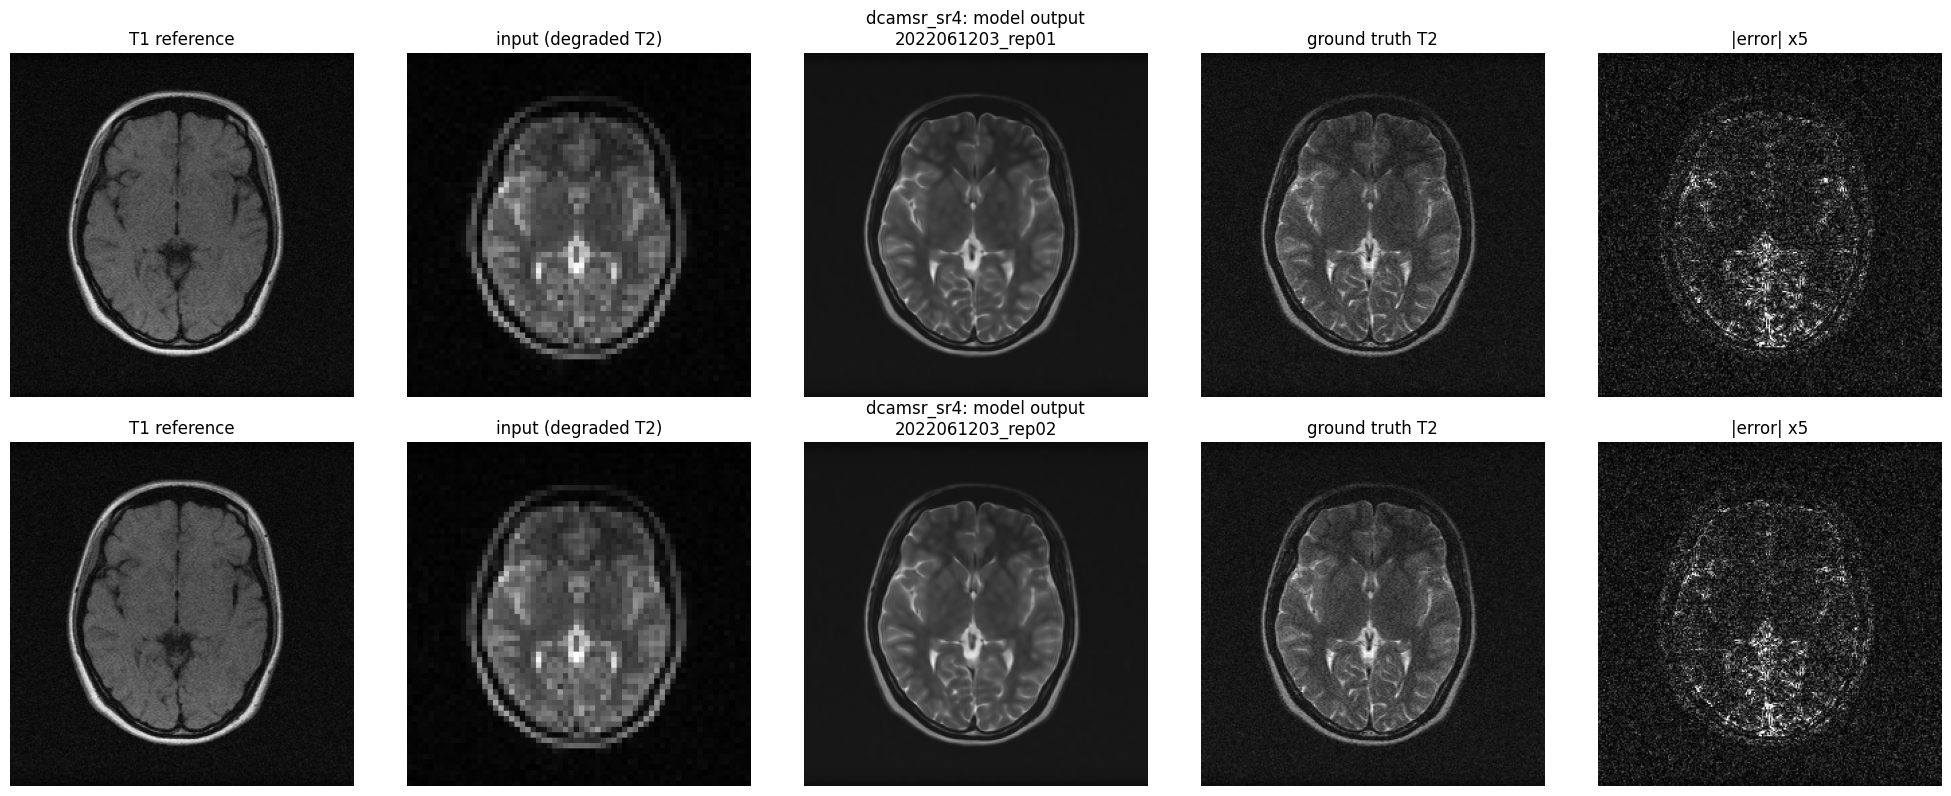

[17:59:17] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
[18:01:31] preloaded 90 volumes / 1620 slices (0.8 GB) in 1 s
sgf_mri_sr4 efficiency: {'params_M': 4.1275, 'sec_per_slice': 0.1118, 'peak_mem_MB': 227.438}


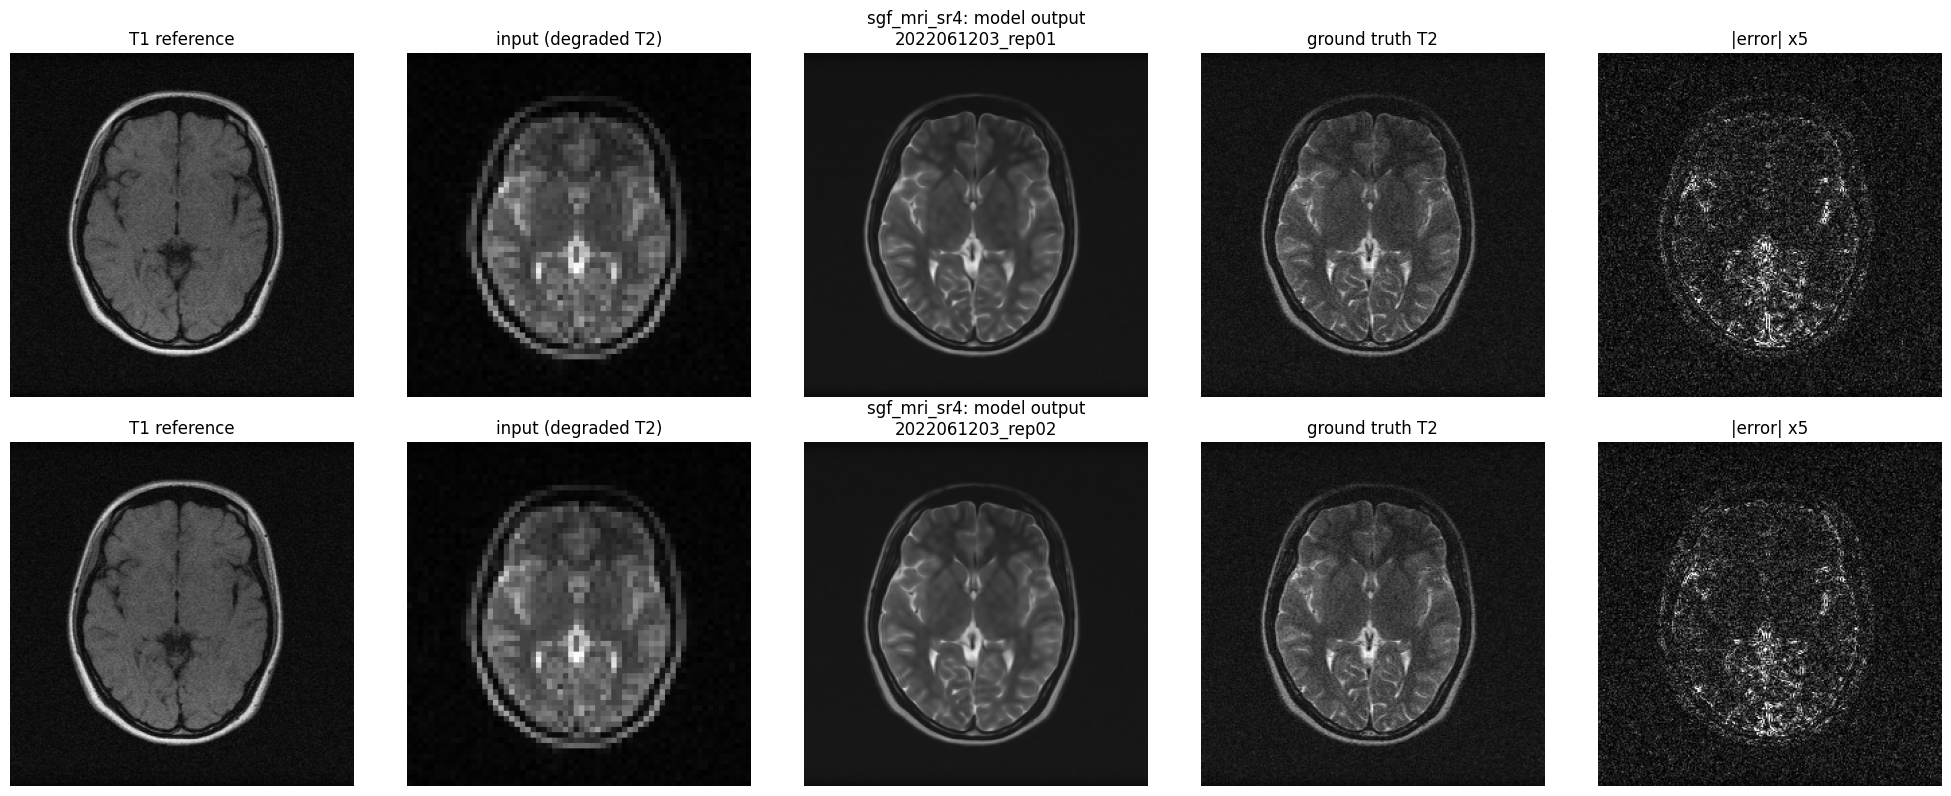

[18:03:55] preloaded 90 volumes / 1620 slices (1.0 GB) in 1 s
[18:05:31] preloaded 90 volumes / 1620 slices (1.0 GB) in 1 s
dcamsr_sr2 efficiency: {'params_M': 9.2867, 'sec_per_slice': 0.0855, 'peak_mem_MB': 487.2437}


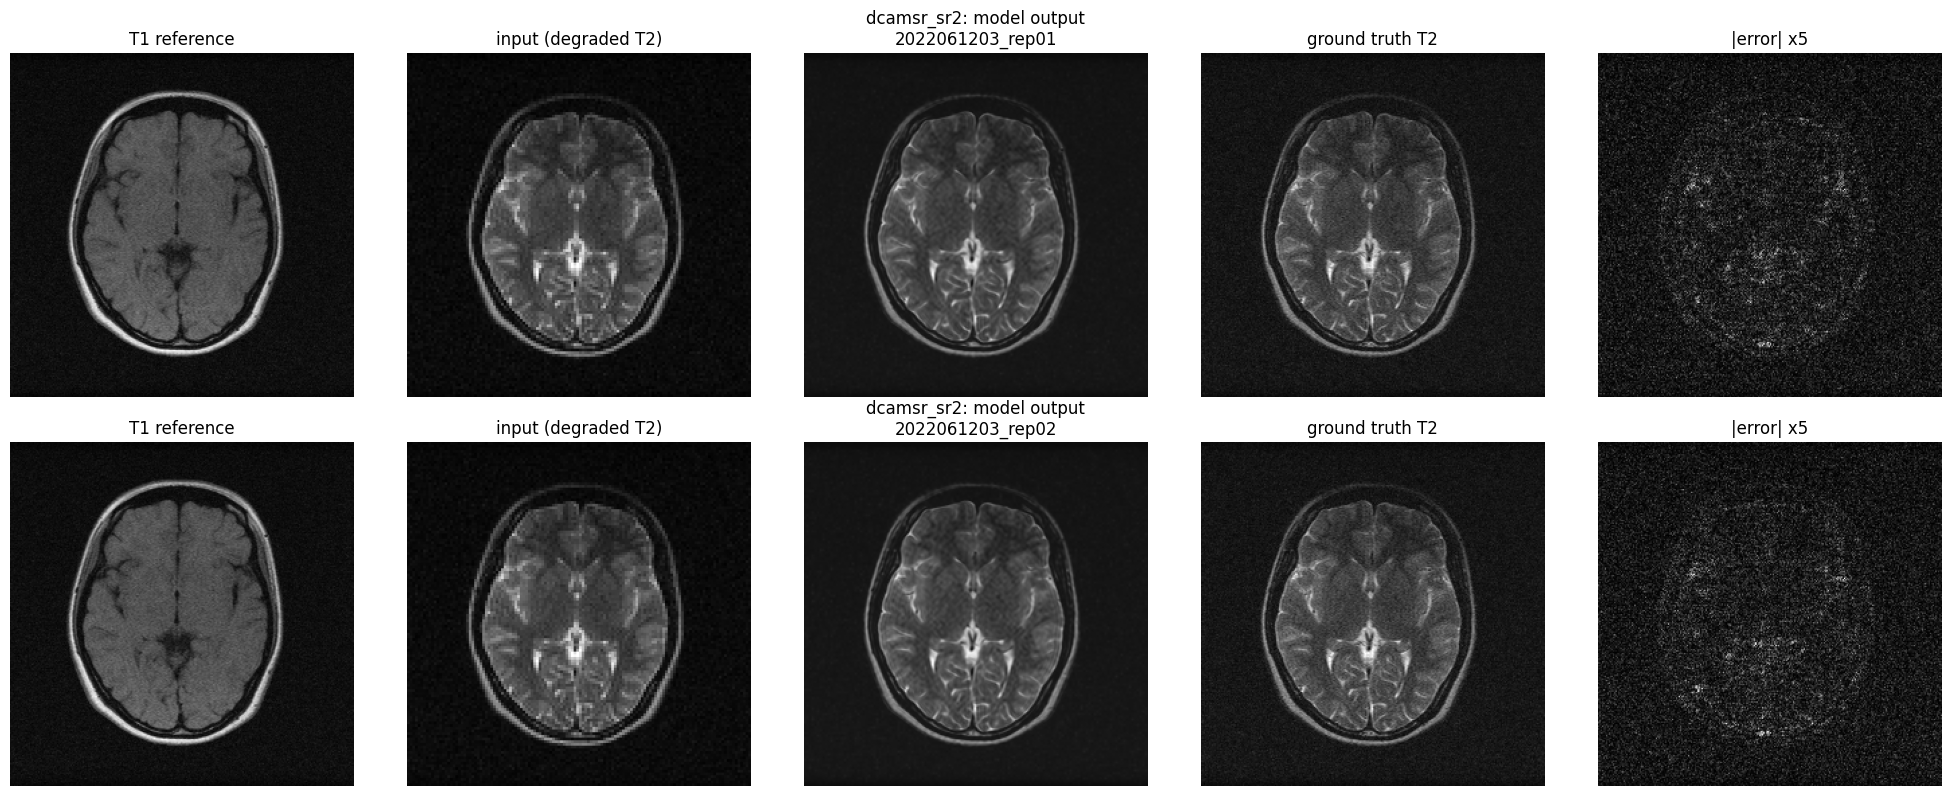

[18:07:10] preloaded 90 volumes / 1620 slices (1.0 GB) in 1 s
[18:09:24] preloaded 90 volumes / 1620 slices (1.0 GB) in 1 s
sgf_mri_sr2 efficiency: {'params_M': 4.1275, 'sec_per_slice': 0.1122, 'peak_mem_MB': 227.5317}


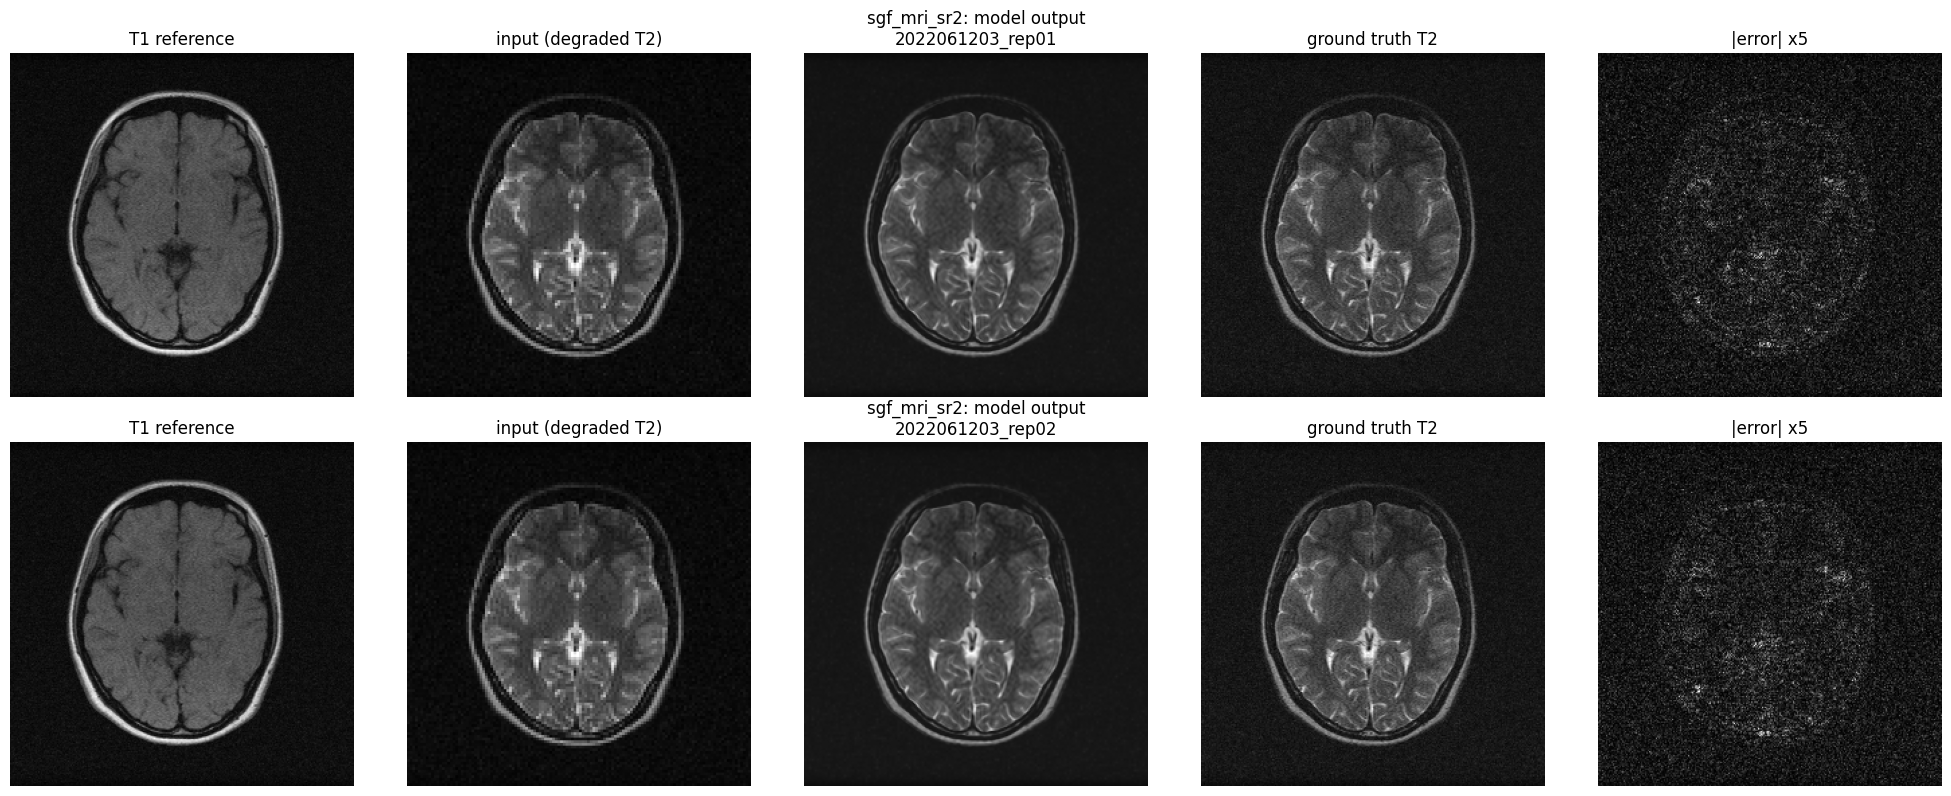

,run,setting,checkpoint,PSNR,± sd,SSIM,paper DCAMSR,paper SGF-MRI,eval min
0,unet_single_sr4,sr x4,best (ep 24),29.60,0.61,0.7081,30.48,30.62,0.2
1,unet_single_sr4,sr x4,last (ep 49),29.50,0.61,0.7076,30.48,30.62,0.2
2,unet_multi_sr4,sr x4,best (ep 44),30.28,0.65,0.7256,30.48,30.62,0.2
3,unet_multi_sr4,sr x4,last (ep 49),30.27,0.65,0.7257,30.48,30.62,0.2
4,dcamsr_sr4,sr x4,best (ep 29),30.59,0.65,0.7308,30.48,30.62,1.4
5,dcamsr_sr4,sr x4,last (ep 49),30.54,0.66,0.7312,30.48,30.62,1.5
6,sgf_mri_sr4,sr x4,best (ep 19),30.61,0.65,0.7313,30.48,30.62,2.2
7,sgf_mri_sr4,sr x4,last (ep 49),30.56,0.66,0.7316,30.48,30.62,2.2
8,dcamsr_sr2,sr x2,best (ep 24),32.42,0.60,0.7808,32.31,32.42,1.5
9,dcamsr_sr2,sr x2,last (ep 49),32.36,0.61,0.7804,32.31,32.42,1.5


In [9]:
PER = {}
if DO_EVAL:
    import matplotlib.pyplot as plt
    rows = []
    for name in COMPARE:
        for which in ["best", "last"]:
            got = load_run(name, which, DEVICE)
            if got is None:
                print(f"{name}/{which}: not found (train it, or attach the notebook that trained it)"); continue
            model, cfg, ep = got
            ds = T.make_dataset(CACHE_DIR, "val", cfg)
            t0 = time.time()
            m, ex = evaluate(model, ds, DEVICE, num_workers=2, keep_examples=2)
            PER[(name, which)] = m["per_volume"]
            T.save_per_volume(m, f"/kaggle/working/per_volume/{name}_{which}.csv")
            key = paper_key(cfg)
            rows.append({"run": name, "setting": f"{cfg.task} x{key[1]}", "checkpoint": f"{which} (ep {ep})",
                         "PSNR": round(m["psnr"], 2), "± sd": round(m["psnr_std"], 2), "SSIM": round(m["ssim"], 4),
                         "paper DCAMSR": PAPER_M4RAW[key]["DCAMSR"][0], "paper SGF-MRI": PAPER_M4RAW[key]["SGF-MRI"][0],
                         "eval min": round((time.time() - t0) / 60, 1)})
            append_result({"run": name, "checkpoint": which, "epoch": ep, "task": cfg.task, "factor": key[1],
                           "model": cfg.model, **{k: m[k] for k in ("psnr", "psnr_std", "ssim", "ssim_std")}})
        if got is not None and cfg.model in ("dcamsr", "sgf_mri"):
            print(name, "efficiency:", {k: round(v, 4) for k, v in profile(model, cfg).items()})
            fig, axes = plt.subplots(len(ex), 5, figsize=(20, 4 * len(ex)), squeeze=False)
            for r, e in zip(axes, ex):
                hw = e["target"].shape
                inp = e["input"] if e["input"].shape == hw else np.kron(e["input"], np.ones((hw[0] // e["input"].shape[0],) * 2))
                vmax = e["target"].max()
                for a, img, t in zip(r, [e["ref"], inp, e["output"], e["target"], np.abs(e["output"] - e["target"])],
                                     ["T1 reference", "input (degraded T2)", "model output", "ground truth T2", "|error| x5"]):
                    own = t in ("T1 reference", "input (degraded T2)")
                    a.imshow(img * (5 if t.startswith("|") else 1), cmap="gray", vmin=None if own else 0, vmax=None if own else vmax)
                    a.set_title(f"{name}: {t}\n{e['name']}" if t == "model output" else t); a.axis("off")
            plt.tight_layout(); plt.show()
        del got
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
    display(pd.DataFrame(rows))

In [10]:
if PER:
    rows = []
    for which in ["last", "best"]:
        names = [n for n in COMPARE if (n, which) in PER]
        for i, a in enumerate(names):
            for b in names[:i]:
                ka, kb = a.rsplit("_", 1)[-1], b.rsplit("_", 1)[-1]      # e.g. sr4: only compare the same setting
                if ka != kb:
                    continue
                for metric in ["psnr", "ssim"]:
                    for level in ["subject", "volume"]:
                        r = T.paired_test(PER[(a, which)], PER[(b, which)], metric, level)
                        unit = "dB" if metric == "psnr" else ""
                        rows.append({"checkpoint": which, "A vs B": f"{a} vs {b}", "metric": metric.upper(),
                                     "level": f"{level} (n={r['n']})",
                                     "A - B": f"{r['mean_diff']:+.4f} ± {r['ci95']:.4f} {unit}",
                                     "t-test p": f"{r['t_p']:.2g} {T.stars(r['t_p'])}",
                                     "Wilcoxon p": f"{r['wilcoxon_p']:.2g} {T.stars(r['wilcoxon_p'])}",
                                     "A wins": f"{r['wins']}/{r['n']}"})
    display(pd.DataFrame(rows))
    print("* p<0.05  ** p<0.01  *** p<0.001  n.s. = not significant")

,checkpoint,A vs B,metric,level,A - B,t-test p,Wilcoxon p,A wins
0,last,unet_multi_sr4 vs unet_single_sr4,PSNR,subject (n=30),+0.7755 ± 0.1309 dB,7.2e-13 ***,1.3e-08 ***,29/30
1,last,unet_multi_sr4 vs unet_single_sr4,PSNR,volume (n=90),+0.7755 ± 0.0730 dB,2.1e-36 ***,5.2e-16 ***,87/90
2,last,unet_multi_sr4 vs unet_single_sr4,SSIM,subject (n=30),+0.0181 ± 0.0030,3.3e-13 ***,1.3e-08 ***,29/30
3,last,unet_multi_sr4 vs unet_single_sr4,SSIM,volume (n=90),+0.0181 ± 0.0017,2.1e-37 ***,4.7e-16 ***,87/90
4,last,dcamsr_sr4 vs unet_single_sr4,PSNR,subject (n=30),+1.0410 ± 0.1368 dB,1.3e-15 ***,3.7e-09 ***,29/30
5,last,dcamsr_sr4 vs unet_single_sr4,PSNR,volume (n=90),+1.0410 ± 0.0764 dB,9.5e-45 ***,2.1e-16 ***,87/90
6,last,dcamsr_sr4 vs unet_single_sr4,SSIM,subject (n=30),+0.0236 ± 0.0031,8.2e-16 ***,3.7e-09 ***,29/30
7,last,dcamsr_sr4 vs unet_single_sr4,SSIM,volume (n=90),+0.0236 ± 0.0017,2.3e-45 ***,2.1e-16 ***,87/90
8,last,dcamsr_sr4 vs unet_multi_sr4,PSNR,subject (n=30),+0.2656 ± 0.0198 dB,2.8e-22 ***,1.9e-09 ***,30/30
9,last,dcamsr_sr4 vs unet_multi_sr4,PSNR,volume (n=90),+0.2656 ± 0.0116 dB,1.8e-63 ***,1.7e-16 ***,90/90


* p<0.05  ** p<0.01  *** p<0.001  n.s. = not significant


In [11]:
if torch.cuda.is_available():
    rows = []
    for size in (256, 320):
        for model_name in ["unet_multi", "dcamsr", "sgf_mri"]:
            c = Config(model=model_name, task="sr", scale=4, img_size=size)
            model = T.build_model(c).to(DEVICE)
            r = profile(model, c, repeats=30)          # resets the GPU memory peak itself, after warm-up
            rows.append({"image": f"{size}x{size}", "model": model_name, "params (M)": round(r["params_M"], 2),
                         "time per slice (ms)": round(1000 * r["sec_per_slice"], 1),
                         "peak GPU memory (MB)": round(r["peak_mem_MB"]) if "peak_mem_MB" in r else None})
            del model; torch.cuda.empty_cache()
    display(pd.DataFrame(rows))
else:
    print("needs a GPU")

,image,model,params (M),time per slice (ms),peak GPU memory (MB)
0,256x256,unet_multi,1.93,5.8,54
1,256x256,dcamsr,9.29,84.5,487
2,256x256,sgf_mri,4.13,111.4,227
3,320x320,unet_multi,1.93,9.9,74
4,320x320,dcamsr,12.38,137.2,758
5,320x320,sgf_mri,4.13,180.3,349


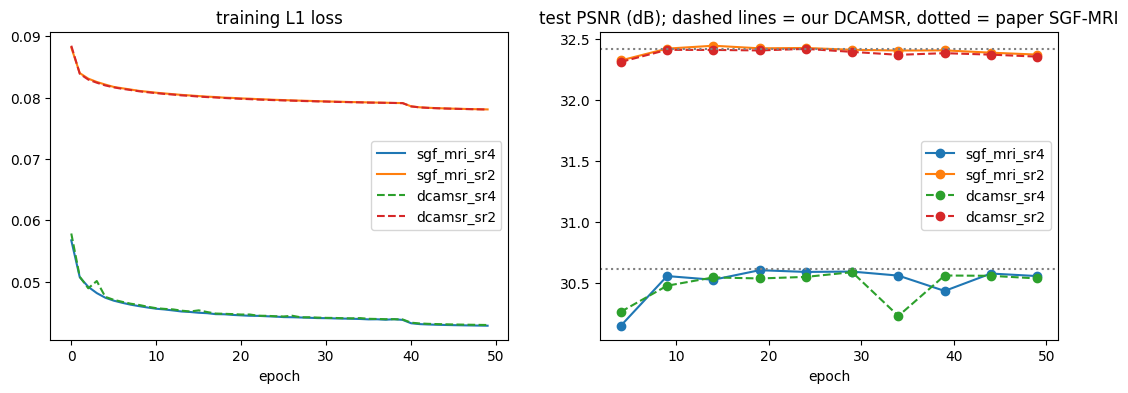

In [12]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in [j.run_name for j in JOBS] + ["dcamsr_sr4", "dcamsr_sr2"]:
    d = T.find_run_dir(name)
    log = d / "log.csv" if d else None
    if log is None or not log.exists():
        continue
    h = pd.read_csv(log)
    ax[0].plot(h.epoch, h.train_l1, label=name, ls="--" if "dcamsr" in name else "-")
    if "psnr" in h:
        v = h.dropna(subset=["psnr"]); ax[1].plot(v.epoch, v.psnr, "o--" if "dcamsr" in name else "o-", label=name)
for j in JOBS:
    ax[1].axhline(PAPER_M4RAW[paper_key(j)]["SGF-MRI"][0], ls=":", c="gray")
ax[0].set(title="training L1 loss", xlabel="epoch"); ax[0].legend()
ax[1].set(title="test PSNR (dB); dashed lines = our DCAMSR, dotted = paper SGF-MRI", xlabel="epoch"); ax[1].legend()
plt.show()